In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)

from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('/content/used-bikes.csv')
df.head()

,Summary,url,Title,Post_Details,Bike Type,Brand,Trim/Edition,Model,Year,Mileage,Seller,Capacity,Price
0,"Atv beach bike 201435,000 kmKegalle, Motorbike...",https://ikman.lk/en/ad/atv-beach-bike-2014-for...,Atv beach bike 2014,"Posted on 30 Jan 9:02 am, Kegalle City, Kegalle",Quadricycles,Other brand,Atv beach bike,Other model,2014,"35,000 km",lakee,150 cc,"Rs 440,000"
1,"Bajaj Pulsar 150 palsar 201450,737 kmAnuradhap...",https://ikman.lk/en/ad/bajaj-pulsar-150-palsar...,Bajaj Pulsar 150 palsar 2014,"Posted on 11 Mar 1:58 pm, Kekirawa, Anuradhapura",Motorbikes,Bajaj,palsar 150,Pulsar 150,2014,"50,737 km",Sasila Ishan,150 cc,"Rs 370,000"
2,"Beach Buggy 20055,000 kmColombo, MotorbikesRs ...",https://ikman.lk/en/ad/beach-buggy-2005-for-sa...,Beach Buggy 2005,"Posted on 21 Jan 9:45 pm, Talawatugoda, Colombo",Quadricycles,Other brand,Beach Buggy,Other model,2005,"5,000 km",vinuka automart,125 cc,"Rs 210,000"
3,"Electra Alpha Vino 2019600 kmColombo, Motorbik...",https://ikman.lk/en/ad/electra-alfa-vino-2019-...,Electra Alpha Vino 2019,"Posted on 22 Feb 2:26 pm, Moratuwa, Colombo",E-bikes,Electra,Vino,Alpha,2019,600 km,Jeewantha Basnayaka,49 cc,"Rs 105,000"
4,"Hero Maestro Edge 201818,500 kmMEMBERKalutara,...",https://ikman.lk/en/ad/hero-maestro-edge-2018-...,Hero Maestro Edge 2018,"Posted on 07 Mar 2:08 pm, Bandaragama, Kalutara",Scooters,Hero,2018,Maestro Edge,2018,"18,500 km",Anjalee Motors,110 cc,"Rs 80,000"


In [3]:
print("Shape:", df.shape)
print("\nColumn Info:")
df.info()

print("\nStatiscal summary:")
display(df.describe(include='all'))

Shape: (5016, 13)

Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5016 entries, 0 to 5015
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Summary       5016 non-null   object
 1   url           5016 non-null   object
 2   Title         5016 non-null   object
 3   Post_Details  5016 non-null   object
 4   Bike Type     5016 non-null   object
 5   Brand         5016 non-null   object
 6   Trim/Edition  3815 non-null   object
 7   Model         5016 non-null   object
 8   Year          5016 non-null   int64 
 9   Mileage       5016 non-null   object
 10  Seller        5013 non-null   object
 11  Capacity      5016 non-null   object
 12  Price         5016 non-null   object
dtypes: int64(1), object(12)
memory usage: 509.6+ KB

Statiscal summary:


,Summary,url,Title,Post_Details,Bike Type,Brand,Trim/Edition,Model,Year,Mileage,Seller,Capacity,Price
count,5016,5016,5016,5016,5016,5016,3815,5016,5016.000000,5016,5013,5016,5016
unique,5007,5016,2504,4248,4,24,1253,188,NaN,1226,3194,90,489
top,"Honda Dio DX Model 201910,000 kmHambantota, Mo...",https://ikman.lk/en/ad/atv-beach-bike-2014-for...,Honda Dio 2018,"Posted on 23 Feb 8:48 am, Piliyandala, Colombo",Motorbikes,Bajaj,.,Dio,NaN,"50,000 km",Piliyandala Scooty Mart,150 cc,"Rs 250,000"
freq,2,1,82,220,3605,1585,147,554,NaN,143,274,943,102
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.234250,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.364404,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1923.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018.000000,NaN,NaN,NaN,NaN


In [4]:
print("Missing values per colum:")
display(df.isnull().sum())

print("\nNo of duplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
display(df.nunique())

Missing values per colum:


,0
Summary,0
url,0
Title,0
Post_Details,0
Bike Type,0
Brand,0
Trim/Edition,1201
Model,0
Year,0
Mileage,0



No of duplicate rows: 0

Unique values per column:


,0
Summary,5007
url,5016
Title,2504
Post_Details,4248
Bike Type,4
Brand,24
Trim/Edition,1253
Model,188
Year,50
Mileage,1226


count           5016
unique           489
top       Rs 250,000
freq             102
Name: Price, dtype: object


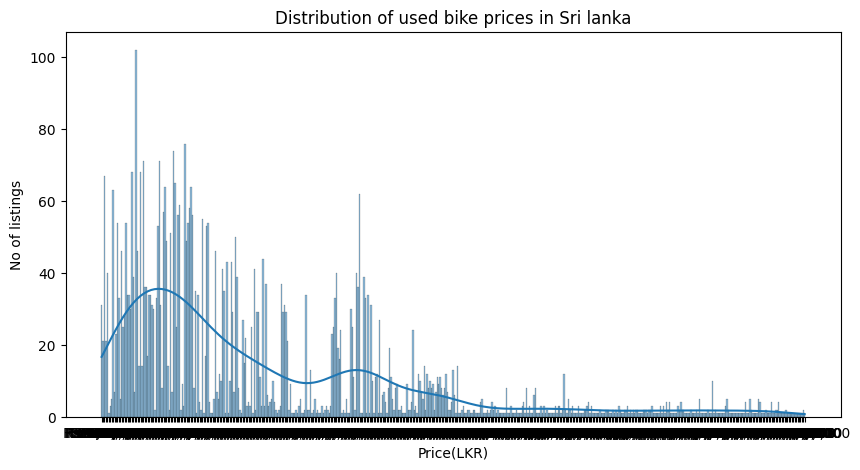

In [5]:
print(df['Price'].describe())

plt.figure(figsize=(10,5))
sns.histplot(df['Price'], bins=50, kde=True)

plt.title('Distribution of used bike prices in Sri lanka')
plt.xlabel('Price(LKR)')
plt.ylabel('No of listings')
plt.show()

In [7]:
df_clean = df.copy()

df_clean['Price'] = (
    df_clean['Price']
    .str.replace('Rs', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df_clean['Mileage'] = (
    df_clean['Mileage']
    .str.replace('km', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df_clean['Capacity'] = (
    df_clean['Capacity']
    .str.replace('cc', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

for column in ['Price', 'Mileage', 'Capacity']:
    df_clean[column] = pd.to_numeric(df_clean[column], errors='coerce')

display(df_clean[['Price', 'Mileage', 'Capacity']].head())

print("\nData types:")
print(df_clean[['Price', 'Mileage', 'Capacity']].dtypes)

print("\nMissing values after conversion:")
print(df_clean[['Price', 'Mileage', 'Capacity']].isnull().sum())

,Price,Mileage,Capacity
0,440000,35000,150
1,370000,50737,150
2,210000,5000,125
3,105000,600,49
4,80000,18500,110



Data types:
Price       int64
Mileage     int64
Capacity    int64
dtype: object

Missing values after conversion:
Price       0
Mileage     0
Capacity    0
dtype: int64


In [8]:
print("Price stats:")
display(df_clean['Price'].describe())
print("\nLowest 10 prices:")
display(df_clean.nsmallest(10, 'Price')[['Brand', 'Model', 'Year', 'Price']])

print("\nHighest 10 prices:")
display(df_clean.nlargest(10, 'Price')[['Brand', 'Model', 'Year', 'Price']])

Price stats:


,Price
count,5.016000e+03
mean,3.160362e+05
std,2.356308e+05
min,1.700000e+04
25%,1.500000e+05
50%,2.550000e+05
75%,4.400000e+05
max,2.500000e+06



Lowest 10 prices:


,Brand,Model,Year,Price
3384,Honda,Other Model,2002,17000
3347,Honda,Super Club,1984,25000
4785,Yamaha,Mate,1997,27000
4784,Yamaha,Mate,1994,28000
667,Bajaj,Other Model,2008,30000
3338,Honda,Other Model,1998,30000
3534,Ranomoto,Other Model,2005,34000
2537,Honda,Other Model,1979,35000
3382,Honda,Super Club,2005,35000
4330,Yamaha,Other Model,1997,35000



Highest 10 prices:


,Brand,Model,Year,Price
6,Honda,CBR,2020,2500000
2372,Honda,CBR,2020,2500000
3555,Royal Enfield,Classic,2017,2500000
3717,Triumph,Other Model,2010,2400000
5006,Yamaha,WR,2016,2280000
3553,Royal Enfield,Classic,2019,2250000
3552,Royal Enfield,Classic,2016,1900000
3710,Suzuki,Other Model,2015,1900000
3556,Royal Enfield,Thunderbird,2016,1850000
3192,Honda,Hornet,2017,1750000


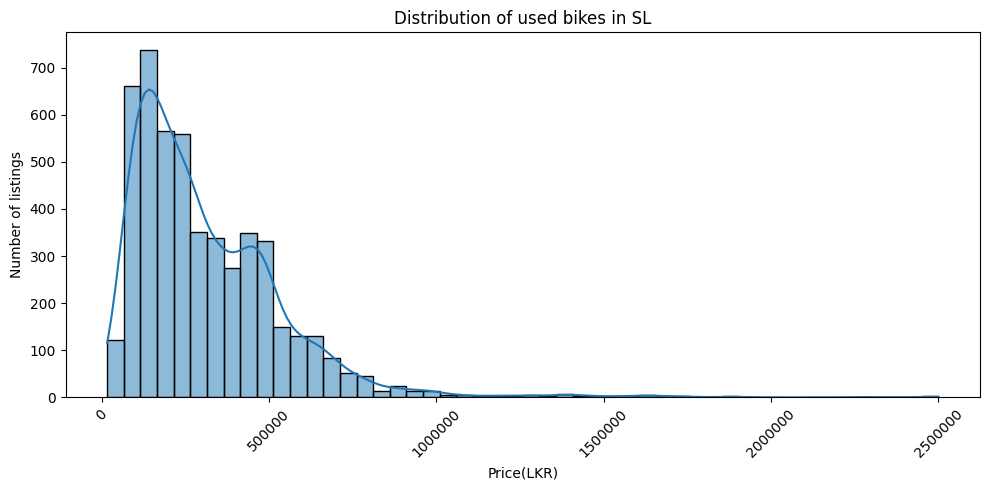

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(df_clean['Price'], bins=50, kde=True)

plt.title('Distribution of used bikes in SL')
plt.xlabel('Price(LKR)')
plt.ylabel('Number of listings')

plt.ticklabel_format(style='plain', axis='x')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

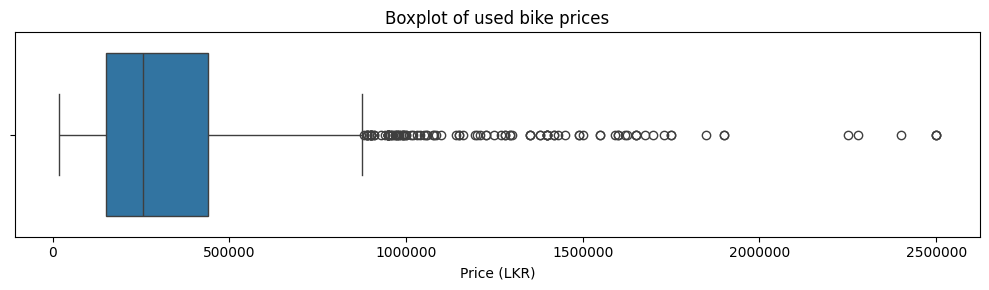

In [10]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=df_clean['Price'])

plt.title('Boxplot of used bike prices')
plt.xlabel('Price (LKR)')

plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

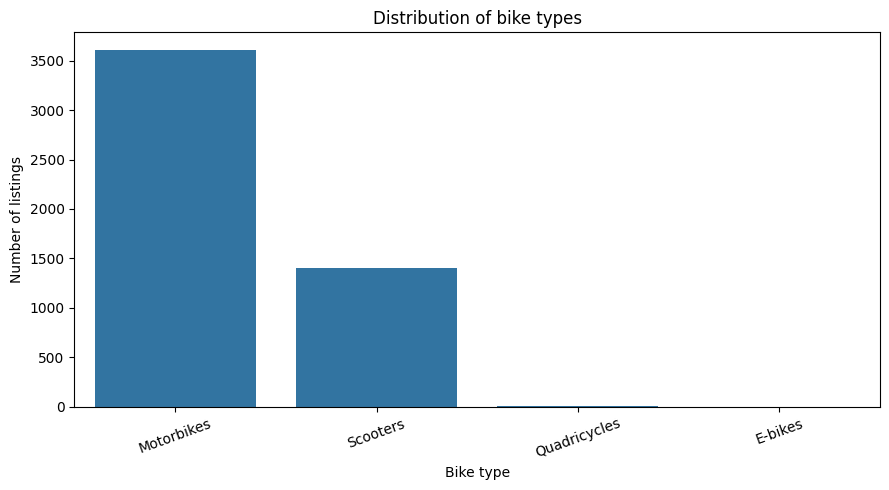

Bike Type
Motorbikes      3605
Scooters        1404
Quadricycles       4
E-bikes            3
Name: count, dtype: int64


In [12]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='Bike Type',
    order=df_clean['Bike Type'].value_counts().index
)

plt.title('Distribution of bike types')
plt.xlabel('Bike type')
plt.ylabel('Number of listings')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(df_clean['Bike Type'].value_counts())

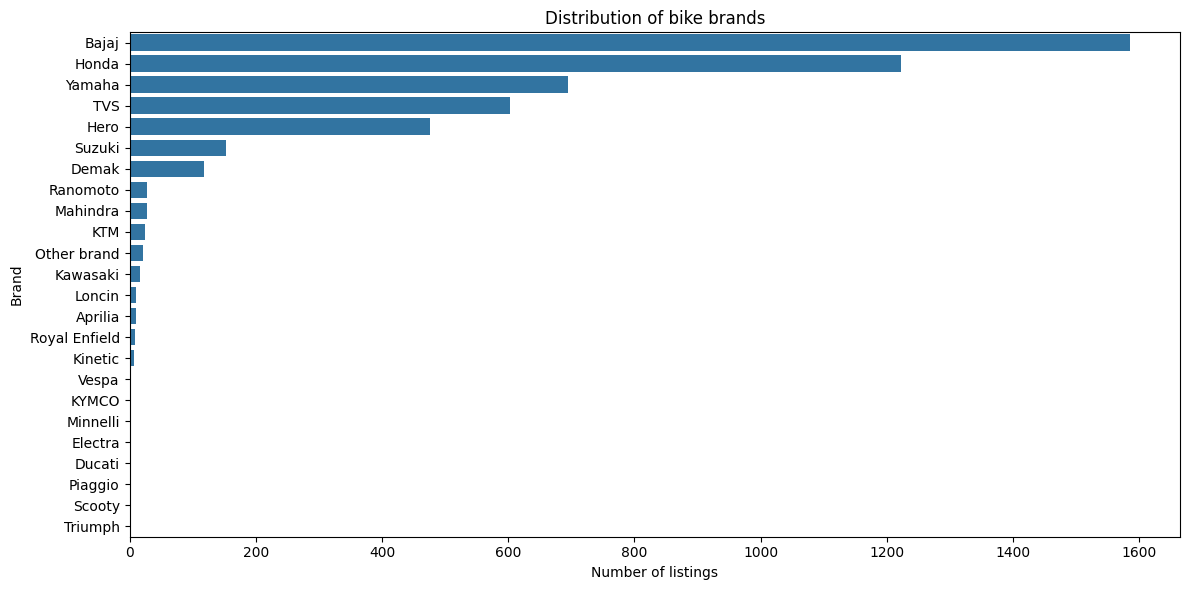

In [13]:
plt.figure(figsize=(12, 6))

brand_counts = df_clean['Brand'].value_counts()

sns.barplot(
    x=brand_counts.values,
    y=brand_counts.index
)

plt.title('Distribution of bike brands')
plt.xlabel('Number of listings')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

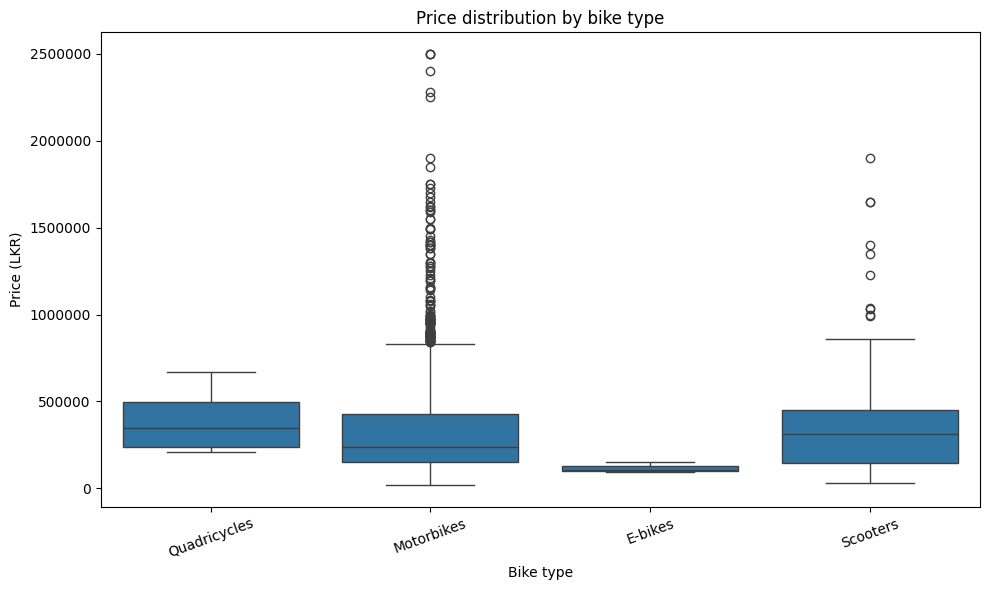

In [14]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='Bike Type',
    y='Price'
)

plt.title('Price distribution by bike type')
plt.xlabel('Bike type')
plt.ylabel('Price (LKR)')
plt.xticks(rotation=20)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

In [15]:
features = [
    'Bike Type',
    'Brand',
    'Trim/Edition',
    'Model',
    'Year',
    'Mileage',
    'Capacity'
]

target = 'Price'

model_df = df_clean[features + [target]].copy()
display(model_df.head())

print("\nDataset shape:", model_df.shape)
print("\nMissing values:")
print(model_df.isnull().sum())
print("\nData types:")
print(model_df.dtypes)

,Bike Type,Brand,Trim/Edition,Model,Year,Mileage,Capacity,Price
0,Quadricycles,Other brand,Atv beach bike,Other model,2014,35000,150,440000
1,Motorbikes,Bajaj,palsar 150,Pulsar 150,2014,50737,150,370000
2,Quadricycles,Other brand,Beach Buggy,Other model,2005,5000,125,210000
3,E-bikes,Electra,Vino,Alpha,2019,600,49,105000
4,Scooters,Hero,2018,Maestro Edge,2018,18500,110,80000



Dataset shape: (5016, 8)

Missing values:
Bike Type          0
Brand              0
Trim/Edition    1201
Model              0
Year               0
Mileage            0
Capacity           0
Price              0
dtype: int64

Data types:
Bike Type       object
Brand           object
Trim/Edition    object
Model           object
Year             int64
Mileage          int64
Capacity         int64
Price            int64
dtype: object


In [16]:
from sklearn.model_selection import train_test_split

X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training set shape: (4012, 7)
Testing set shape: (1004, 7)

Training target shape: (4012,)
Testing target shape: (1004,)


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = [
    'Bike Type',
    'Brand',
    'Trim/Edition',
    'Model'
]

numerical_features = [
    'Year',
    'Mileage',
    'Capacity'
]

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=5
    ))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('cat', categorical_transformer, categorical_features),
    ('num', numerical_transformer, numerical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [18]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
print("Preprocessing completed.")

Training data after preprocessing: (4012, 222)
Testing data after preprocessing: (1004, 222)
Preprocessing completed.


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)
rf_predictions = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print(f"MAE:  {rf_mae:,.2f}")
print(f"RMSE: {rf_rmse:,.2f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Results
---------------------
MAE:  91,538.99
RMSE: 144,565.26
R²:   0.5962


In [20]:
results = []

results.append({
    'Model': 'Random Forest',
    'Ensemble': 'Bagging',
    'MAE': rf_mae,
    'RMSE': rf_rmse,
    'R2': rf_r2
})

results_df = pd.DataFrame(results)

display(results_df)

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.987482,144565.26106,0.596218


,Feature,Importance
221,num__Capacity,0.327020
219,num__Year,0.208105
220,num__Mileage,0.140578
161,cat__Model_Hornet,0.028165
15,cat__Brand_Royal Enfield,0.025597
177,cat__Model_PCX,0.017195
128,cat__Model_CD 200,0.013534
18,cat__Brand_Yamaha,0.013525
112,cat__Trim/Edition_infrequent_sklearn,0.011734
91,cat__Trim/Edition_Unknown,0.011533


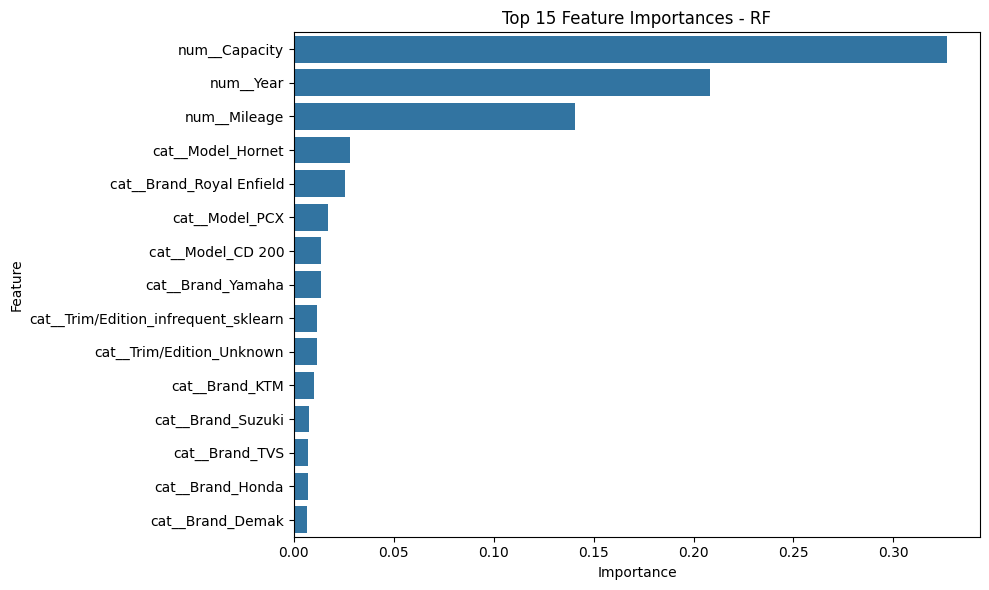

In [22]:
feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

# DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)
display(feature_importance_df.head(15))
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Feature Importances - RF')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Random Forest Feature Importance Analysis**

The feature importance analysis indicates that numerical specifications contribute significantly to used-bike price prediction. Engine capacity is the most influential feature (32.70%), followed by manufacturing year (20.81%) and mileage (14.06%). Together, these three features account for approximately 67.6% of the model's total impurity-based feature importance.

Among categorical features, specific models such as Hornet and PCX, as well as brands such as Royal Enfield and Yamaha, show relatively higher importance. This suggests that both technical specifications and brand/model characteristics provide useful information for predicting used-bike prices.

The analysis also highlights the importance of handling missing and infrequent categorical values during preprocessing. However, impurity-based feature importance can favour certain types of features, so these results should be interpreted with caution.

In [23]:
!pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 41.1 MB/s  0:00:02


In [24]:
from xgboost import XGBRegressor

# XGBoost model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective='reg:squarederror',
    n_jobs=-1
)
xgb_model.fit(X_train_processed, y_train)
xgb_predictions = xgb_model.predict(X_test_processed)

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBoost Results")
print("---------------------")
print(f"MAE:  {xgb_mae:,.2f}")
print(f"RMSE: {xgb_rmse:,.2f}")
print(f"R²:   {xgb_r2:.4f}")

XGBoost Results
---------------------
MAE:  94,623.25
RMSE: 141,070.76
R²:   0.6155


In [25]:
results.append({
    'Model': 'XGBoost',
    'Ensemble': 'Boosting',
    'MAE': xgb_mae,
    'RMSE': xgb_rmse,
    'R2': xgb_r2
})

results_df = pd.DataFrame(results)

display(results_df)

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.987482,144565.261060,0.596218
1,XGBoost,Boosting,94623.250000,141070.757849,0.615502


In [26]:
from lightgbm import LGBMRegressor

# LightGBM model
lgbm_model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)
lgbm_model.fit(X_train_processed, y_train)
lgbm_predictions = lgbm_model.predict(X_test_processed)

lgbm_mae = mean_absolute_error(y_test, lgbm_predictions)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, lgbm_predictions))
lgbm_r2 = r2_score(y_test, lgbm_predictions)

print("LightGBM Results")
print("---------------------")
print(f"MAE:  {lgbm_mae:,.2f}")
print(f"RMSE: {lgbm_rmse:,.2f}")
print(f"R²:   {lgbm_r2:.4f}")

LightGBM Results
---------------------
MAE:  99,753.41
RMSE: 156,498.17
R²:   0.5268


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [27]:
results.append({
    'Model': 'LightGBM',
    'Ensemble': 'Boosting',
    'MAE': lgbm_mae,
    'RMSE': lgbm_rmse,
    'R2': lgbm_r2
})

results_df = pd.DataFrame(results)
display(results_df)

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.987482,144565.261060,0.596218
1,XGBoost,Boosting,94623.250000,141070.757849,0.615502
2,LightGBM,Boosting,99753.414333,156498.174820,0.526807


In [28]:
from catboost import CatBoostRegressor

# CatBoost model
cat_model = CatBoostRegressor(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    random_seed=42,
    verbose=0
)
cat_model.fit(X_train_processed, y_train)
cat_predictions = cat_model.predict(X_test_processed)

cat_mae = mean_absolute_error(y_test, cat_predictions)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_predictions))
cat_r2 = r2_score(y_test, cat_predictions)

print("CatBoost Results")
print("---------------------")
print(f"MAE:  {cat_mae:,.2f}")
print(f"RMSE: {cat_rmse:,.2f}")
print(f"R²:   {cat_r2:.4f}")

CatBoost Results
---------------------
MAE:  102,292.12
RMSE: 147,768.62
R²:   0.5781


In [29]:
results.append({
    'Model': 'CatBoost',
    'Ensemble': 'Boosting',
    'MAE': cat_mae,
    'RMSE': cat_rmse,
    'R2': cat_r2
})

results_df = pd.DataFrame(results)
display(results_df)

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.987482,144565.261060,0.596218
1,XGBoost,Boosting,94623.250000,141070.757849,0.615502
2,LightGBM,Boosting,99753.414333,156498.174820,0.526807
3,CatBoost,Boosting,102292.116006,147768.615841,0.578125


In [30]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge

base_models = [
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )),
    ('xgb', XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        objective='reg:squarederror',
        n_jobs=1
    )),
    ('lgbm', LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1,
        n_jobs=1
    ))
]

# stacking model
stack_model = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(),
    cv=5,
    n_jobs=-1
)
stack_model.fit(X_train_processed, y_train)
stack_predictions = stack_model.predict(X_test_processed)

stack_mae = mean_absolute_error(y_test, stack_predictions)
stack_rmse = np.sqrt(mean_squared_error(y_test, stack_predictions))
stack_r2 = r2_score(y_test, stack_predictions)

print("Stacking Results")
print("---------------------")
print(f"MAE:  {stack_mae:,.2f}")
print(f"RMSE: {stack_rmse:,.2f}")
print(f"R²:   {stack_r2:.4f}")

Stacking Results
---------------------
MAE:  92,993.64
RMSE: 141,023.89
R²:   0.6158


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [31]:
results.append({
    'Model': 'Stacking (RF + XGB + LGBM)',
    'Ensemble': 'Stacking',
    'MAE': stack_mae,
    'RMSE': stack_rmse,
    'R2': stack_r2
})

results_df = pd.DataFrame(results)
display(results_df)

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.987482,144565.261060,0.596218
1,XGBoost,Boosting,94623.250000,141070.757849,0.615502
2,LightGBM,Boosting,99753.414333,156498.174820,0.526807
3,CatBoost,Boosting,102292.116006,147768.615841,0.578125
4,Stacking (RF + XGB + LGBM),Stacking,92993.641695,141023.885412,0.615758


In [32]:
from sklearn.preprocessing import StandardScaler

# preprocessing pipeline for numerical features and categorical features
from sklearn.compose import ColumnTransformer

ann_preprocessor = ColumnTransformer(transformers=[
    ('cat', categorical_transformer, categorical_features),
    ('num', Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numerical_features)
])

X_train_ann = ann_preprocessor.fit_transform(X_train)
X_test_ann = ann_preprocessor.transform(X_test)

print("ANN training data shape:", X_train_ann.shape)
print("ANN testing data shape:", X_test_ann.shape)
print("ANN preprocessing completed.")

ANN training data shape: (4012, 222)
ANN testing data shape: (1004, 222)
ANN preprocessing completed.


In [33]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# random seed for reproducibility
tf.random.set_seed(42)

# ANN
ann_model = Sequential([
    Input(shape=(X_train_ann.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

ann_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

ann_history = ann_model.fit(
    X_train_ann,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 159275253760.0000 - mae: 318523.9375 - val_loss: 146863489024.0000 - val_mae: 309774.1875
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 158989172736.0000 - mae: 318094.9688 - val_loss: 146227494912.0000 - val_mae: 308795.7812
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 157751574528.0000 - mae: 316238.0625 - val_loss: 144281354240.0000 - val_mae: 305789.9375
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 154867302400.0000 - mae: 311870.0938 - val_loss: 140421480448.0000 - val_mae: 299745.4062
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 149825437696.0000 - mae: 304084.0312 - val_loss: 134268805120.0000 - val_mae: 289855.1875
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 142380580864.0000 - mae: 292201.3125 - val_loss: 125745725440.0000 - val_mae: 275571.8750
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 132605493248.0000 - mae: 275863.

In [34]:
ann_predictions = ann_model.predict(X_test_ann).flatten()

ann_mae = mean_absolute_error(y_test, ann_predictions)
ann_rmse = np.sqrt(mean_squared_error(y_test, ann_predictions))
ann_r2 = r2_score(y_test, ann_predictions)

print("ANN Results")
print("---------------------")
print(f"MAE:  {ann_mae:,.2f}")
print(f"RMSE: {ann_rmse:,.2f}")
print(f"R²:   {ann_r2:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step
ANN Results
---------------------
MAE:  119,197.77
RMSE: 186,605.34
R²:   0.3272


In [35]:
# Combine RF and ANN predictions
hybrid_predictions = (
    0.5 * rf_predictions +
    0.5 * ann_predictions
)

hybrid_mae = mean_absolute_error(y_test, hybrid_predictions)
hybrid_rmse = np.sqrt(mean_squared_error(y_test, hybrid_predictions))
hybrid_r2 = r2_score(y_test, hybrid_predictions)

print("Hybrid Model (Random Forest + ANN) Results")
print("------------------------------------------")
print(f"MAE:  {hybrid_mae:,.2f}")
print(f"RMSE: {hybrid_rmse:,.2f}")
print(f"R²:   {hybrid_r2:.4f}")

Hybrid Model (Random Forest + ANN) Results
------------------------------------------
MAE:  98,887.79
RMSE: 150,052.62
R²:   0.5650


In [36]:
results.append({
    'Model': 'Hybrid (RF + ANN)',
    'Ensemble': 'Hybrid',
    'MAE': hybrid_mae,
    'RMSE': hybrid_rmse,
    'R2': hybrid_r2
})

results_df = pd.DataFrame(results)
display(results_df)

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.987482,144565.261060,0.596218
1,XGBoost,Boosting,94623.250000,141070.757849,0.615502
2,LightGBM,Boosting,99753.414333,156498.174820,0.526807
3,CatBoost,Boosting,102292.116006,147768.615841,0.578125
4,Stacking (RF + XGB + LGBM),Stacking,92993.641695,141023.885412,0.615758
5,Hybrid (RF + ANN),Hybrid,98887.786546,150052.616207,0.564983


In [37]:
from sklearn.model_selection import RandomizedSearchCV

rf_parameter_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.8, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=rf_parameter_grid,
    n_iter=10,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_processed, y_train)

print("Best Parameters:")
print(rf_search.best_params_)

print(f"\nBest Cross-Validation RMSE: {-rf_search.best_score_:,.2f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 20}

Best Cross-Validation RMSE: 152,664.58


In [38]:
# best tuned RF model
tuned_rf_model = rf_search.best_estimator_
tuned_rf_predictions = tuned_rf_model.predict(X_test_processed)

tuned_rf_mae = mean_absolute_error(y_test, tuned_rf_predictions)
tuned_rf_rmse = np.sqrt(mean_squared_error(y_test, tuned_rf_predictions))
tuned_rf_r2 = r2_score(y_test, tuned_rf_predictions)

print("Tuned RF Results")
print("---------------------------")
print(f"MAE:  {tuned_rf_mae:,.2f}")
print(f"RMSE: {tuned_rf_rmse:,.2f}")
print(f"R²:   {tuned_rf_r2:.4f}")

print("\nBaseline RF Results")
print("------------------------------")
print(f"MAE:  {rf_mae:,.2f}")
print(f"RMSE: {rf_rmse:,.2f}")
print(f"R²:   {rf_r2:.4f}")

Tuned RF Results
---------------------------
MAE:  92,579.22
RMSE: 144,742.70
R²:   0.5952

Baseline RF Results
------------------------------
MAE:  91,538.99
RMSE: 144,565.26
R²:   0.5962


In [39]:
results.append({
    'Model': 'Tuned Random Forest',
    'Ensemble': 'Bagging (Tuned)',
    'MAE': tuned_rf_mae,
    'RMSE': tuned_rf_rmse,
    'R2': tuned_rf_r2
})

results_df = pd.DataFrame(results)
display(results_df.round(2))

,Model,Ensemble,MAE,RMSE,R2
0,Random Forest,Bagging,91538.99,144565.26,0.60
1,XGBoost,Boosting,94623.25,141070.76,0.62
2,LightGBM,Boosting,99753.41,156498.17,0.53
3,CatBoost,Boosting,102292.12,147768.62,0.58
4,Stacking (RF + XGB + LGBM),Stacking,92993.64,141023.89,0.62
5,Hybrid (RF + ANN),Hybrid,98887.79,150052.62,0.56
6,Tuned Random Forest,Bagging (Tuned),92579.22,144742.70,0.60


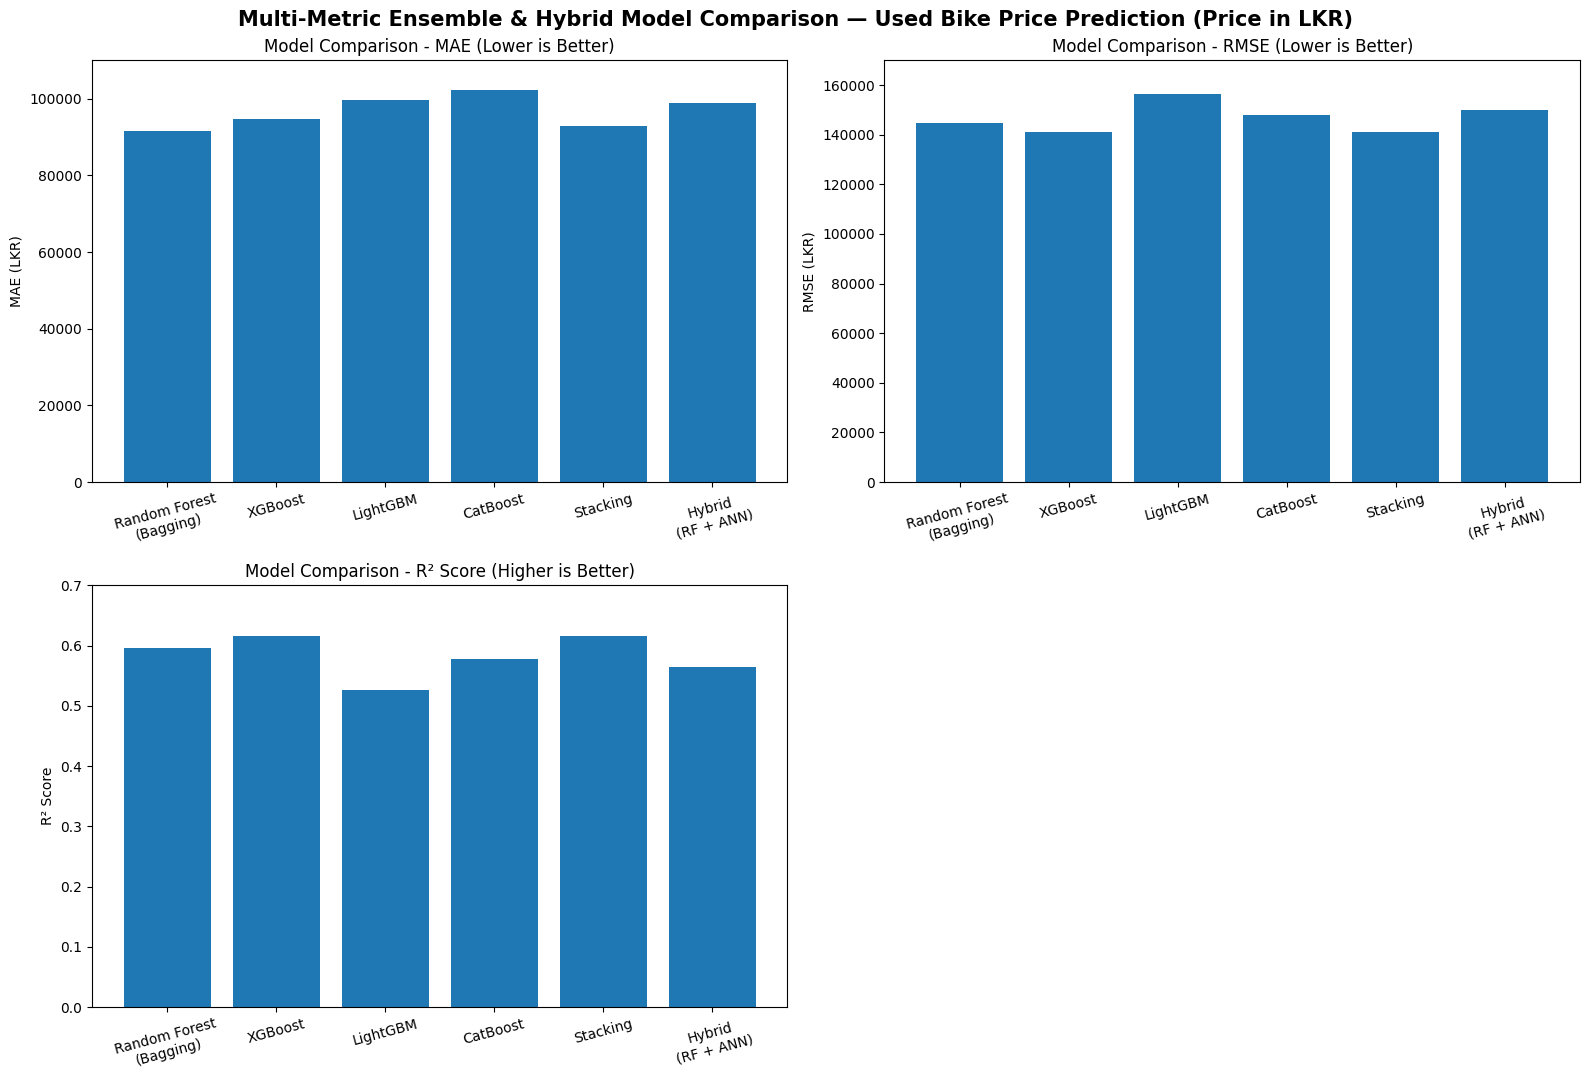

In [42]:
import matplotlib.pyplot as plt
import numpy as np

comparison_df = results_df[
    results_df['Model'] != 'Tuned Random Forest'
].copy()

model_labels = [
    'Random Forest\n(Bagging)',
    'XGBoost',
    'LightGBM',
    'CatBoost',
    'Stacking',
    'Hybrid\n(RF + ANN)'
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# MAE chart
axes[0, 0].bar(model_labels, comparison_df['MAE'])
axes[0, 0].set_title('Model Comparison - MAE (Lower is Better)')
axes[0, 0].set_ylabel('MAE (LKR)')
axes[0, 0].set_ylim(0, 110000)
axes[0, 0].set_yticks(np.arange(0, 110001, 20000))
axes[0, 0].tick_params(axis='x', rotation=15)

# RMSE chart
axes[0, 1].bar(model_labels, comparison_df['RMSE'])
axes[0, 1].set_title('Model Comparison - RMSE (Lower is Better)')
axes[0, 1].set_ylabel('RMSE (LKR)')
axes[0, 1].set_ylim(0, 170000)
axes[0, 1].set_yticks(np.arange(0, 170001, 20000))
axes[0, 1].tick_params(axis='x', rotation=15)

# R² chart
axes[1, 0].bar(model_labels, comparison_df['R2'])
axes[1, 0].set_title('Model Comparison - R² Score (Higher is Better)')
axes[1, 0].set_ylabel('R² Score')
axes[1, 0].set_ylim(0, 0.7)
axes[1, 0].set_yticks(np.arange(0, 0.71, 0.1))
axes[1, 0].tick_params(axis='x', rotation=15)

axes[1, 1].axis('off')

fig.suptitle(
    'Multi-Metric Ensemble & Hybrid Model Comparison — '
    'Used Bike Price Prediction (Price in LKR)',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [44]:
import joblib
import os

os.makedirs('saved_models', exist_ok=True)

models = {
    'random_forest': rf_model,
    'xgboost': xgb_model,
    'lightgbm': lgbm_model,
    'catboost': cat_model,
    'stacking': stack_model
}

for name, model in models.items():
    joblib.dump(model, f'saved_models/{name}.pkl')

joblib.dump(preprocessor, 'saved_models/preprocessor.pkl')
joblib.dump(ann_preprocessor, 'saved_models/ann_preprocessor.pkl')

ann_model.save('saved_models/ann_model.keras')

feature_importance_df.to_csv(
    'saved_models/feature_importance.csv',
    index=False
)

results_df.to_csv(
    'saved_models/model_results.csv',
    index=False
)

print("All models and supporting files saved successfully!")

All models and supporting files saved successfully!


In [45]:
import shutil

shutil.make_archive(
    'saved_models',
    'zip',
    'saved_models'
)

from google.colab import files
files.download('saved_models.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
xgb_model.save_model('xgboost_model.json')